# Exploring the gold layer

The warehouse built by `make build` is a single DuckDB file. This notebook opens it read-only,
loads the gold models into pandas, and draws a ready-made chart of off-ball runs per player.

**Before you start:** run `make setup ingest build` once, then `make notebook`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

WAREHOUSE = Path("../data/warehouse/football.duckdb")
assert WAREHOUSE.exists(), "No warehouse yet: run `make ingest build` from the project root."

con = duckdb.connect(str(WAREHOUSE), read_only=True)


def q(sql: str) -> pd.DataFrame:
    """Run a query against the warehouse and return a DataFrame."""
    return con.sql(sql).df()


# One look for every chart: thin marks, recessive grid, no top/right spines.
BLUE, INK, MUTED, GRID = "#2a78d6", "#0f1720", "#7a8594", "#e9edf1"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 1,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})

## What's in the warehouse

Every model lives in a schema named after its layer (`main_bronze`, `main_silver`, `main_gold`).

In [2]:
q("""
    select schema_name as layer, table_name as model, estimated_size as approx_rows
    from duckdb_tables()
    order by layer, model
""")

,layer,model,approx_rows
0,main_bronze,bronze_dynamic_events,94361
1,main_bronze,bronze_match_players,719
2,main_bronze,bronze_matches,20
3,main_gold,gold_player_match_metrics,623
4,main_gold,gold_team_match_summary,40
5,main_gold,gold_team_season_summary,13
6,main_silver,silver_matches,20
7,main_silver,silver_off_ball_runs,9898
8,main_silver,silver_on_ball_engagements,17445
9,main_silver,silver_passing_options,48308


## Load the gold models

Three tables, three grains: team × season, team × match, player × match.

In [3]:
teams = q("select * from main_gold.gold_team_season_summary")
team_matches = q("select * from main_gold.gold_team_match_summary")
players = q("select * from main_gold.gold_player_match_metrics")

print(f"{len(teams)} teams · {team_matches.match_id.nunique()} matches · "
      f"{players.player_id.nunique()} players")
teams[["team_name", "matches_in_sample", "off_ball_runs_per_30_tip", "engagements_per_30_otip"]] \
    .sort_values("off_ball_runs_per_30_tip", ascending=False)

13 teams · 20 matches · 271 players


,team_name,matches_in_sample,off_ball_runs_per_30_tip,engagements_per_30_otip
9,Newcastle,1,336.49,490.03
12,Auckland FC,7,305.33,524.83
7,Western United,4,298.47,514.25
5,Perth Glory,2,297.46,483.39
2,Melbourne V FC,4,295.34,493.29
1,Wellington P FC,3,268.73,534.04
6,Brisbane FC,3,266.99,456.72
0,Adelaide United,3,265.29,535.60
3,Sydney FC,2,265.26,540.61
8,Macarthur FC,2,265.25,476.96


## Chart · Most active runners

Season rates are built from **summed** counts and minutes, never by averaging per-match rates (the
same rule the gold season model follows). Only players with at least 45 minutes in possession (about two full
matches) qualify, so a short cameo can't top the list. Teams appear 1 to 7 times in the sample, so
players from teams with more matches are more likely to qualify.

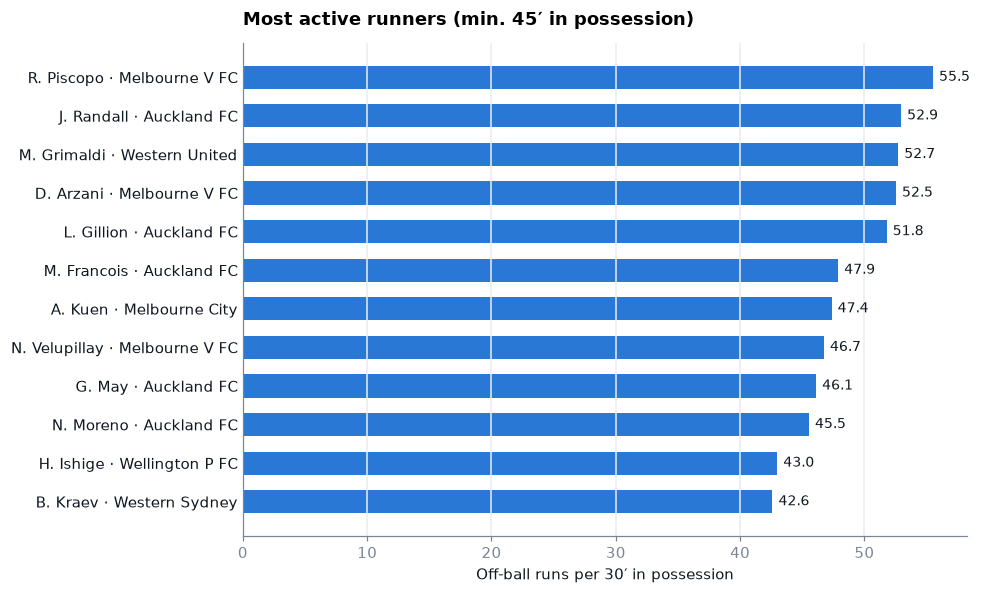

In [4]:
MIN_TIP = 45

runners = q(f"""
    select player_name,
           team_name,
           count(*)                                   as matches,
           sum(minutes_tip)                           as minutes_tip,
           sum(off_ball_runs)                         as off_ball_runs,
           sum(off_ball_runs) / sum(minutes_tip) * 30 as runs_per_30_tip
    from main_gold.gold_player_match_metrics
    group by player_name, team_name
    having sum(minutes_tip) >= {MIN_TIP}
    order by runs_per_30_tip desc
    limit 12
""").iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(runners.player_name + " · " + runners.team_name, runners.runs_per_30_tip,
               height=0.6, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.1f}" for v in runners.runs_per_30_tip], padding=4, fontsize=9,
             color=INK)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
ax.set_xlabel("Off-ball runs per 30′ in possession")
ax.set_title(f"Most active runners (min. {MIN_TIP}′ in possession)", pad=12)
fig.tight_layout()
plt.show()

## Your turn

- Swap a metric: every rate column in `teams` and `players` ends in `_per_30_tip` or `_per_30_otip`.
- Filter one team: `players.query("team_name == 'Auckland FC'")`.
- Write SQL directly: `q("select ... from main_gold....")`.

When you're done, close the connection so `make build` can write to the file again.

In [5]:
con.close()